In [ ]:
import numpy as np
import math

from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

from src.problem_model import TorqueDistributionProblem, model
from src.classes import CarParams, Reference, WeelTork, Vehicle_state
from src.vehicle_physics import generate_torque_reference, vehicle_dynamics
from src.grid import  dijkstra, dijkstra_reverso, plot_trajectory, build_cost_map



A função abaixo plota a curva de pareto dada a solução

## Definição dos parametros


Essa seção define os parametros fisicos do carrinho

In [3]:
# Definindo parametros do veículo
car_params = CarParams(
    wheel_radius=0.10,      # m
    gear_ratio=1.0,         # -
    track_width=0.40,       # m

    T_min=-1,              # N.m
    T_max=5,              # N.m

    loss_coeff=0.5,
    Ploss_scale=1000.0,     # W

    mass=12.0,              # kg
    yaw_inertia=0.80        # kg.m²
)


In [4]:
race = [
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 1, 1, 1, 1, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100, 100, 1, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 1, 1, 1000, 1, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100, 100, 100],
    [100, 100, 100, 1, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100, 100],
    [100, 100, 1, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100],
    [100, 1, 100, 100, 100, 1, 1, 1, 100, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100],
    [100, 1, 100, 100, 100, 1, 100, 100, 1, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100],
    [100, 1, 100, 100, 100, 1, 1, 100, 100, 1, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100],
    [100, 100, 1, 100, 100, 100, 100, 1, 100, 1, 1, 100, 100, 100, 100, 1, 100, 100, 100, 100],
    [100, 100, 100, 1, 100, 100, 100, 1, 100, 100, 100, 1, 100, 100, 1, 100, 100, 100, 100, 100],
    [100, 100, 100, 1, 100, 100, 100, 1, 100, 100, 100, 100, 1, 1, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 1, 1, 1, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
   
]

escale = 1

race = [
    [valor
     for valor in linha
     for _ in range(escale)]
    for linha in race
    for _ in range(escale)
]



Loop principal onde é feita é calculado o caminho e aplicado os torques iterativamente

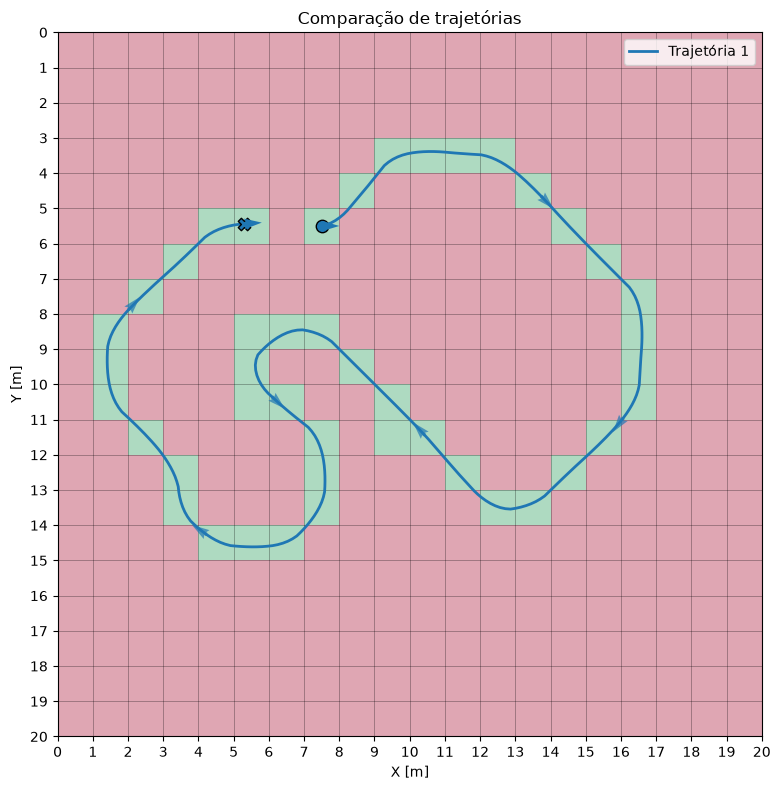

In [5]:

height = 20
width = 20

# grid = build_cost_map(width, height)
grid = race

inicio = (5 * escale, 7 * escale)
destino = (5 * escale, 5 * escale)

caminho = dijkstra(grid, inicio, destino)

CELL_WIDTH = 1 # 10 cm

DT = 0.5

estado_inicial = Vehicle_state(
    X=(inicio[1] + 0.5) * CELL_WIDTH,
    Y=(inicio[0] + 0.5) * CELL_WIDTH,
    psi=(math.pi / 4) * 0,
    vx=0,
    omega=0.0
)

torques_referencia, estados_calculados = generate_torque_reference(
    caminho=caminho,
    estado_inicial=estado_inicial,
    params=car_params,
    cell_width=CELL_WIDTH,
    dt=DT,
    v_ref=0.3
)

plot_trajectory(
    paths=[estados_calculados],
    grid=grid,
    CELL_WIDTH=CELL_WIDTH
)

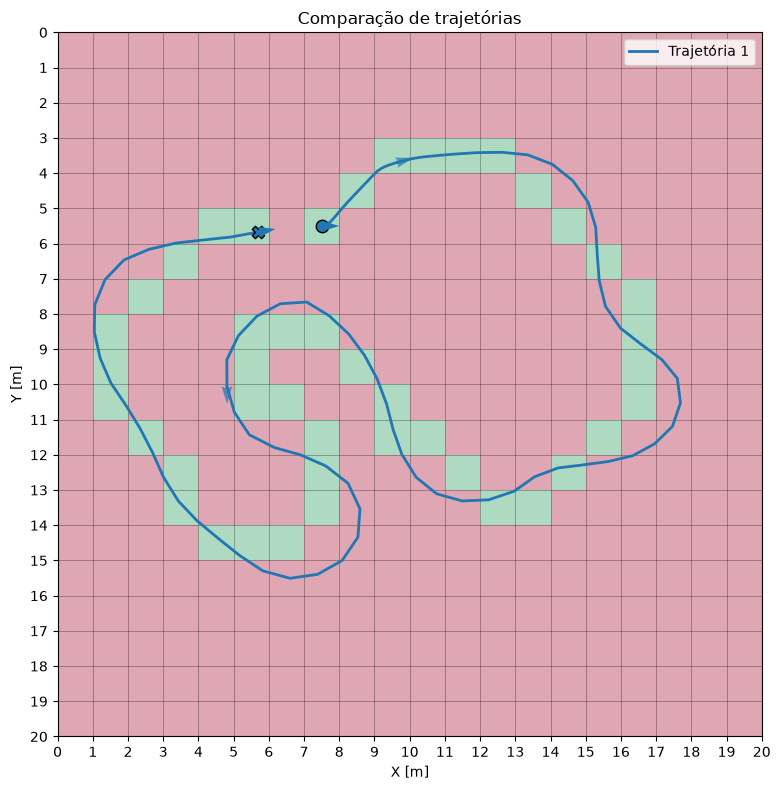

In [6]:
celula_atual = inicio

T_prev = WeelTork(
    Fl=0,
    Fr=0,
    Rl=0,
    Rr=0,
)

estados_calculados_online = [estado_inicial]
torques_otimizado_online = [T_prev]

t = 0

# Definindo algoritmo e quantidade de individuos da população

algorithm = NSGA2(
    pop_size=30,
    eliminate_duplicates=True
)

caminho_dijkstra_reverso = dijkstra_reverso(grid, destino)

while celula_atual != destino:

    if celula_atual not in caminho_dijkstra_reverso.keys():
        print(celula_atual)
        break

    proxima_celula = caminho_dijkstra_reverso[celula_atual]

    # Calcula uma lista de torques necessarios para chegar na proxima celula
    torques_referencia, estados_calculados = generate_torque_reference(
        caminho=[celula_atual, proxima_celula],
        estado_inicial=estados_calculados_online[-1],
        params=car_params,
        cell_width=CELL_WIDTH,
        dt=DT,
        v_ref=0.3
    )

    if len(torques_referencia) == 0:
        print("Sem torque de referencia")
        print(f"Atual: {celula_atual}")
        print(f"proxima: {proxima_celula}")
        break

    # Utiliza apenas a primeira referencia (O carrinho pode mudar de celula após aplicar o torque, portanto aplicamos apenas o primeiro)
    Fx, Mz, Ploss = model(torques_referencia[0], car_params)
    
    # Referências do controlador
    ref = Reference(
        Fx=Fx,
        Mz=Mz
    )
    # Cria o problema com esse torque de referencia para cada roda
    problem = TorqueDistributionProblem(
        params=car_params,
        ref=ref,
        T_prev=torques_otimizado_online[-1]
    )

    # Minimiza para encontrar o torque real
    result = minimize(
        problem,
        algorithm,
        termination=("n_gen", 100),
        seed=1,
        verbose=False
    )

    if len(result.X) == 0:
        print("Nenhuma solução valida encontrada")
        break
    
    # Escolhe uma das soluções de compromisso como referencia
    T_result = result.X[-1]

    if len(T_result) < 4:
        print("Solução estranha")
        break

    T_opt = WeelTork(
        Fl=T_result[0],
        Fr=T_result[1],
        Rl=T_result[2],
        Rr=T_result[3],
    )
    torques_otimizado_online.append(T_opt)

    next_state = vehicle_dynamics(
        T_opt,
        estados_calculados_online[-1],
        car_params,
        DT
    )
    estados_calculados_online.append(next_state)

    celula_atual = (
        int(next_state.Y // CELL_WIDTH),
        int(next_state.X // CELL_WIDTH)
    )

    t += DT

plot_trajectory(
    grid = grid,
    CELL_WIDTH = CELL_WIDTH,
    paths = [estados_calculados_online],
)
